<a href="https://colab.research.google.com/github/LiaIssakov/Portfolio_2025/blob/main/exploring_random_projections_unsolved.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Random projections and finding similar faces

# Random 'projections' (recap)

## (See the illustrations for more details).

We will try to do dimensionality reduction -- but unlike tSNE this will be a linear reduction. We will find a matrix which will do the job for us.

Let's try a seemingly stupid idea: orthogonally project our **data points of dimension $M$** onto the span of an **orthonormal set of $d$** vectors (each of dimension $M$).

> So in the language of the stupid geographic cartoon last time -- we don't even look at where things are, pick our upstream direction at random and project all the points (buildings etc) on this line.

We can express the resulting points in the basis of this (sub)space -- so each data point now has $d$ coordinates. This is simpler than it sounds -- see below!

> A convenient way of thinking about is that we perform a change of basis from the standard basis in $\mathbb{R}^M$ to some other orthonnormal basis (and we now know how it works in detail). One caveat is that technically this other basis isn't the basis of our original space -- but is a basis of its subspace. So we have to be a little careful.

> We could also say that we change the basis (using some orthonnormal matrix of size $M \times M$) -- but then forget about all but $d$ coordinates of this basis.

We will exploit some tricks which will allow us generate such a set of vectors quickly. Don't worry about this too much.

# Task 1 (solved it for you)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.neighbors import KDTree
from sklearn.neighbors import KNeighborsClassifier # for the bonus

np.float64(32.74787687813754)

In [ ]:
def get_random_projection_matrix(M, d):
  '''
  Generate the matrix R we discussed.

  The rows are the vectors (b_1, b_2, ..., b_d).

  Tip: it involved sampling from normal the distribution (randn).
  Tip': np.linalg.norm has a useful argument: keepdims
  '''
  R = np.random.randn(d, M)
  norms = np.linalg.norm(R, axis=1, keepdims=True)
  return R/norms

# New data

## New dataset (olivetti faces)

It's 400 images of faces of 40 people each in 10 different poses.
Each image is of size 64x64.


In [ ]:
faces = fetch_olivetti_faces()
x_train = faces['images']
y_train = faces['target']

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data


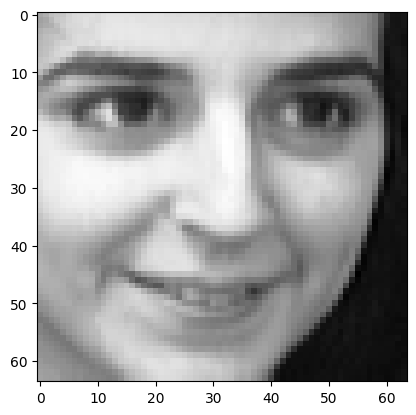

In [ ]:
plt.imshow(x_train[92], cmap='gray')

In [ ]:
M = x_train[0].size # dimension of the original space
n = len(x_train) # number of points
d = 5 # target dimension
R = get_random_projection_matrix(M, d)
assert np.allclose(np.linalg.norm(R, axis=1),1)

In [ ]:
# check JL
eps = 0.75
8/eps**2 * np.log(n)

np.float64(85.21194022553574)

In [ ]:
np.linalg.norm(R[0])

np.float64(1.0)

In [ ]:
x_train.shape

(400, 64, 64)

# Some tips:

> It will be crucial to keep track of what the rows and columns of all our matrices mean.

Some conventions:
- Let's keep data in rows (because most data analysis libraries expect that)
- Let's keep basis vectors as columns of matrices (because that's the usual mathematical convention, and numerical libraries assume that)
- Let store any 'projection' matrix R, s.t. Rp performs the projection.

> We will have to do some transpositions from time to time, but that' better than losing track of what hapenning. Feel free to adopt your own convention -- but be consistent.



# Task 2: Check if R is (approximately) orthonormal


If you think about it (or even better draw it), the code below ($RR^T$) computes the dot product for all pairs of columns in $R$ -- and computes the difference with the identity matrix. If it was 0 it'd mean they are orthonormal.

What would be get for $R^TR$?

> Tip. np.eye(n) gives you the $n \times n$ identity matrix (ones on diagonal zeros everywhere else).

In [ ]:
# todo

# Task 3: implement the actual linear 'projection'

> Implement the function perform_projection below, which should project each point in $X$ onto the span on row vectors of matrix $R$.

> As we checked above the rows of $R$ form an **orthonormal** set of vectors -- at least approximately.

> Remember to keep our conventions! Make sure the resulting data is properly transposed! Otherwise it'll cause problems downstream.

In [ ]:
def perform_projection(X, R):
  return X

# Task 4: Try it out on the face dataset!

> try to find the good d by eyeballing the results, but keep J-S lemma in mind!

> You can also chosse a different face (face_ind variable).

Remember that for small $d$, kd-trees are much faster when you do multiple queries.

In [ ]:
# just reshaping the data and building kd-tree
X = x_train.reshape(len(x_train), -1)

print(X.shape)
# the original dimension is too high, but we just want a single
# query for comparison
kd = KDTree(X) #

(400, 4096)


In [ ]:
def show_faces(X, d, face_ind, k=8):
  '''
  X - original dataset
  d - target dimension
  face_ind - index of the face to look at
  k - nr of most similar faces to look for
  '''
  M = X[0].size
  R = get_random_projection_matrix(M, d)

  X_approx = perform_projection(X, R)

  # here if d is low enough using kd-trees actually makes sense!
  kd_approx = KDTree(X_approx)

  closest_indices_original = kd.query([x_train[face_ind].ravel()],
                k = k, return_distance = False)[0] # ravel means 'flatten'

  closest_indices_reduced = kd_approx.query([X_approx[face_ind].ravel()],
                                  k = k, return_distance = False)[0]
  plt.figure(figsize = (20,10))
  plt.title(f'nearest neighbours for exact d = {M}')
  plt.show(plt.imshow(np.hstack(x_train[closest_indices_original]), cmap = 'gray'))

  plt.figure(figsize = (20,10))
  plt.title(f"nearest neighbours approximate d={d}\n (note that I'm showing the original images, the method just gives us nearest indices based on the reduced representation)")
  plt.show(plt.imshow(np.hstack(x_train[closest_indices_reduced]), cmap='gray'))

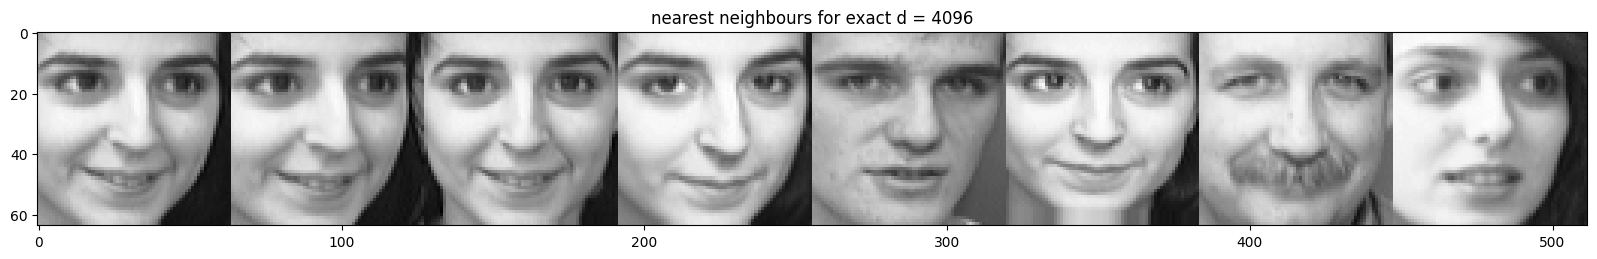

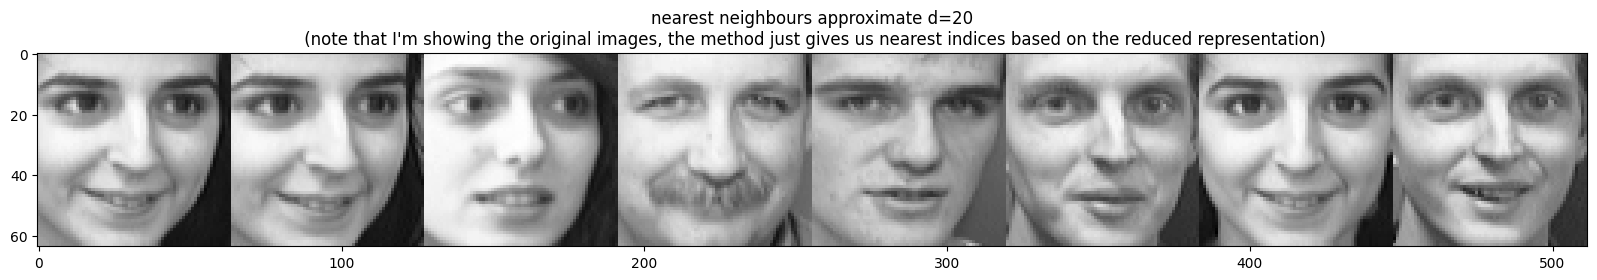

In [ ]:
show_faces(X, d=20, face_ind=92)

## Is this faster?

In [ ]:
%time closest_indices_original = kd.query([x_train[0].ravel()], k=50, return_distance=False)[0]

NameError: name 'kd' is not defined

In [ ]:
X_approx = perform_projection(X, R)
kd_approx = KDTree(X_approx)

In [ ]:
%time closest_indices_reduced = kd_approx.query([X_approx[0].ravel()], k=50, return_distance=False)

CPU times: user 356 µs, sys: 24 µs, total: 380 µs
Wall time: 374 µs


# Johnson-Lindenstrauss lemma (recap)

It's not a conincidence that the above example works!

Let's say our original data is $P ⊂ \mathbb{R}^M$ of size $n$. We want to safely reduce the dimension to $d$.

The Johnson-Lindenstrauss lemma states that if $$d \geq \frac{8}{ϵ^2}\log{n}$$ then there exists a $d \times M$ matrix $R$ such that for each pair of vectors $p,q \in P$, $$ (1-ϵ) \|p-q \|_2^2 \leq \frac{M}{d} \|Rp-Rq \|_2^2 \leq (1+ϵ)\|p-q \|_2^2 $$.

> The **amazing part** is that the formula for the acceptible target dimension $d$ only depends on the number of points, $n$, and **not** the dimension of the original space $M$!

One consequence of this lemma is that if $d$ is roughly $\log{n}$, a **randomly generated** projection matrix (as we did above!) roughly preserves the (squared) Euclidean distances (with high probability).


> Note that the constant $M/d$ could also be incorporated into the projection matrix, but I think it's easier to see what's hapenning this way.




# Extra: Verify that the distances are actually (approximately) preserved.

> Can you try to tune $d$ using the above lemma?

> How does the approximation quality change if you change $d$?



In [ ]:
# just a bunch of index pairs to check
inds = np.random.randint(10, n, size=(10, 2))

d = 200 # target dimension

M = X[0].size
P = X
R = get_random_projection_matrix(M, d)
P2 = perform_projection(P, R)

assert P2.shape[1]==d

for ind1, ind2 in inds:
  p1, p2 = P[ind1], P[ind2]
  q1, q2 = P2[ind1], P2[ind2]

  d1 = np.linalg.norm(p1-p2)**2
  # need to rescale to take into account the dimension change
  d2 = np.linalg.norm(q1-q2)**2 * M/d

  print(f'd1={d1}, d2={d2}, d1/d2 = {d1/(d2+1e-9)}, d2/d1 = {d2/(d1+1e-9)}')

d1=94.76444244384766, d2=90.62985426800766, d1/d2 = 1.045620598291681, d2/d1 = 0.9563698358876545
d1=181.2288360595703, d2=185.6870799185208, d1/d2 = 0.9759905543138342, d2/d1 = 1.0246000799645651
d1=121.20345306396484, d2=121.28158864459529, d1/d2 = 0.9993557506749127, d2/d1 = 1.0006446646416023
d1=199.16293334960938, d2=205.1388628614252, d1/d2 = 0.9708688571759144, d2/d1 = 1.030005229443602
d1=324.6507873535156, d2=304.10945524883255, d1/d2 = 1.0675458514987899, d2/d1 = 0.9367279153328668
d1=127.36290740966797, d2=132.04348235380445, d1/d2 = 0.9645527756337141, d2/d1 = 1.036749906541323
d1=92.82832336425781, d2=94.54330800625237, d1/d2 = 0.9818603275140001, d2/d1 = 1.0184747992836731
d1=68.54546356201172, d2=71.73158111061669, d1/d2 = 0.9555827781817988, d2/d1 = 1.0464818148865906
d1=175.690673828125, d2=190.93681409146717, d1/d2 = 0.920150860708513, d2/d1 = 1.0867783128787882
d1=170.90402221679688, d2=166.65101002484695, d1/d2 = 1.0255204705347438, d2/d1 = 0.9751146161641834


# Extra (but important) task: Check how well we can we classify the identity of people.

Specifically what's the classification accuracy depending on $d$ if we use a knn classifier (imported at the top)?

> It's just meant as quick and dirty test -- we're not even splitting the data into train and test. (You can add this if you want.)